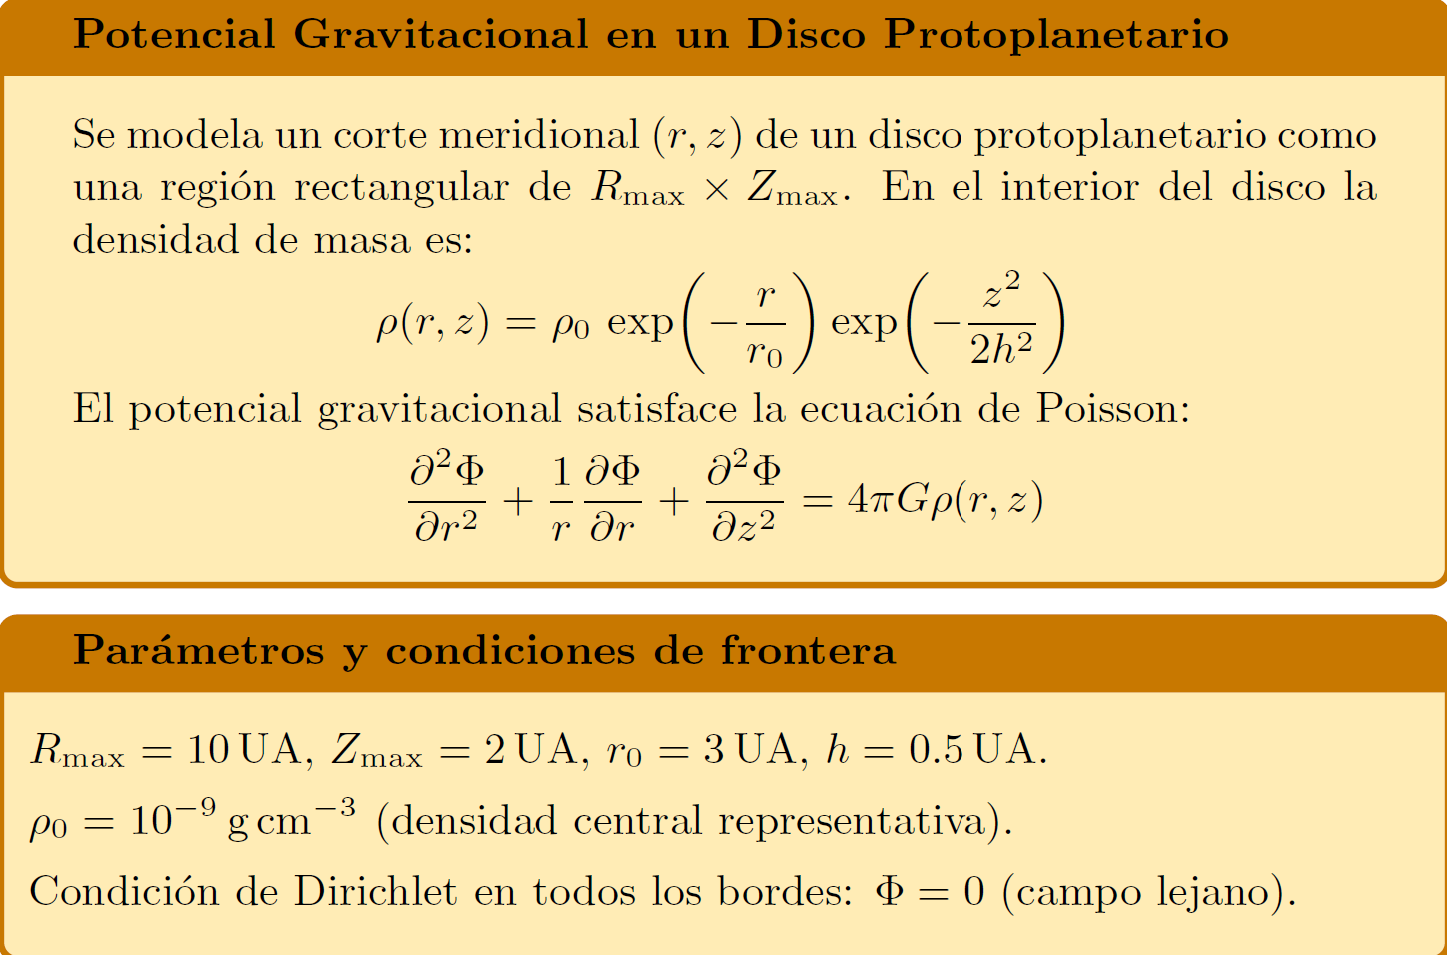

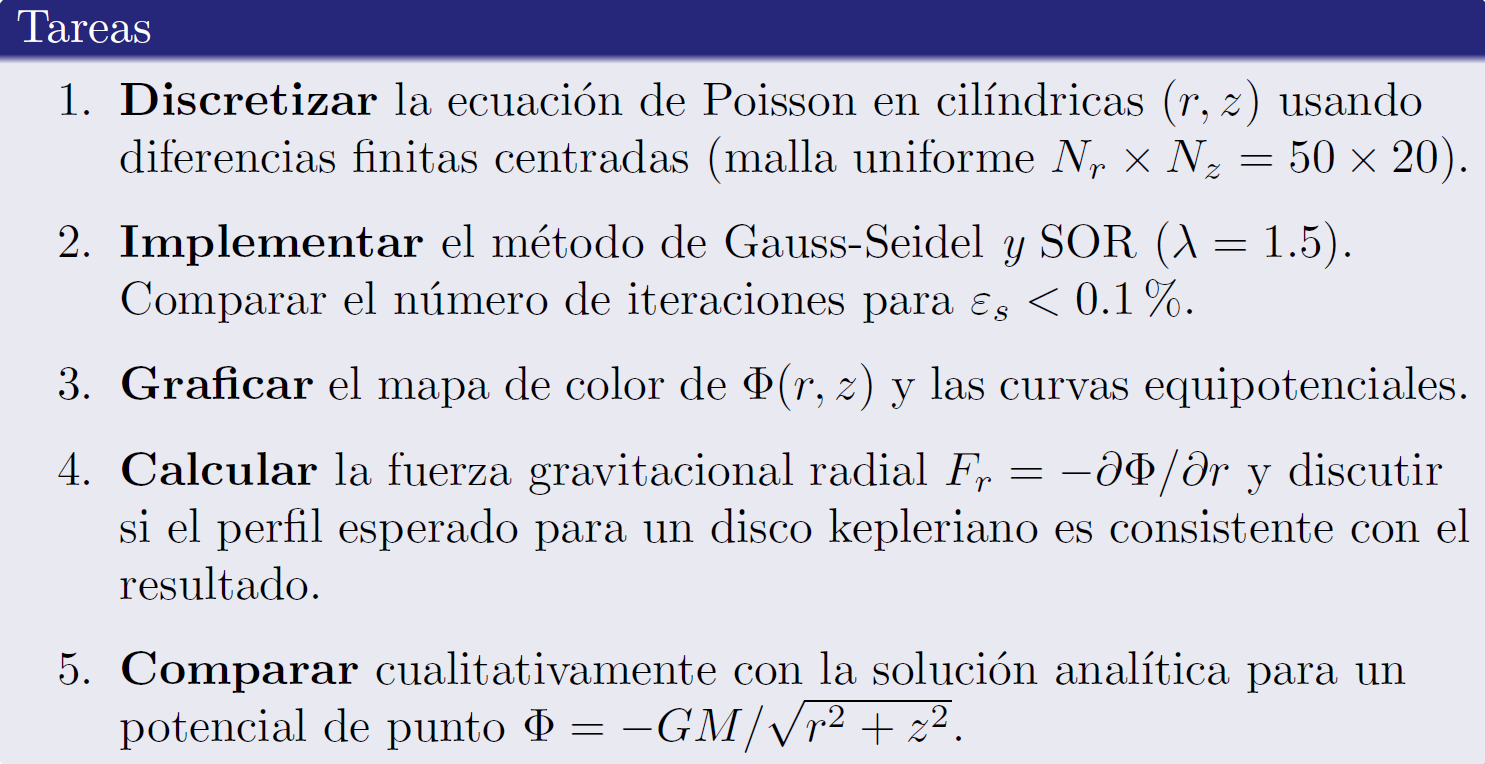

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros físicos
G = 6.6743e-8          #(cm^3 g^-1 s^-2)
UA = 1.495978707e13    # cm
R_max = 10.0 * UA      
Z_max = 2.0 * UA      
r0 = 3.0 * UA          
h = 0.5 * UA           
rho_0 = 1e-9  

# Configuración de la malla espacial
Nr = 50
Nz = 20
dr = R_max / Nr
dz = (2.0 * Z_max) / (2 * Nz)

r = np.linspace(0, R_max, Nr + 1)
z = np.linspace(-Z_max, Z_max, 2 * Nz + 1)


# malla 2D y cálculo analítico de la densidad de masa
R_grid, Z_grid = np.meshgrid(r, z, indexing='ij')

termino_r = np.exp(-R_grid / r0)
termino_z = np.exp(-(Z_grid**2) / (2.0 * h**2))
rho = rho_0 * termino_r * termino_z

In [2]:
# método de Gauss-Seidel

Phi_gs = np.zeros((Nr + 1, len(z)))
Ar = 1.0 / (dr**2)
Az = 1.0 / (dz**2)

tol = 0.1          # Criterio de convergencia 0.1%
error = 100.0
iteracion = 0

while error > tol and iteracion < 2000:
    error_max = 0.0
    Phi_prev = Phi_gs.copy()
    
    for i in range(1, Nr):
        ri = r[i]
        Br = 1.0 / (2.0 * ri * dr)
        for j in range(1, len(z) - 1):
            termino_fuente = 4.0 * np.pi * G * rho[i, j]
            phi_nuevo = ((Ar + Br) * Phi_gs[i+1, j] + 
                         (Ar - Br) * Phi_gs[i-1, j] + 
                         Az * (Phi_gs[i, j+1] + Phi_gs[i, j-1]) - 
                         termino_fuente) / (2.0 * Ar + 2.0 * Az)
            
            if abs(phi_nuevo) > 1e-12:
                err_actual = abs((phi_nuevo - Phi_prev[i, j]) / phi_nuevo) * 100.0
                if err_actual > error_max:
                    error_max = err_actual
            
            Phi_gs[i, j] = phi_nuevo
            
    error = error_max
    iteracion += 1

print("Total iteraciones Gauss-Seidel:", iteracion)

Total iteraciones Gauss-Seidel: 405


In [3]:
#método SOR (lambda = 1.5)

Phi_sor = np.zeros((Nr + 1, len(z)))
lam = 1.5
error_sor = 100.0
iter_sor = 0

while error_sor > tol and iter_sor < 2000:
    error_max = 0.0
    Phi_prev = Phi_sor.copy()
    
    for i in range(1, Nr):
        ri = r[i]
        Br = 1.0 / (2.0 * ri * dr)
        for j in range(1, len(z) - 1):
            termino_fuente = 4.0 * np.pi * G * rho[i, j]
            phi_gs_nuevo = ((Ar + Br) * Phi_sor[i+1, j] + 
                            (Ar - Br) * Phi_sor[i-1, j] + 
                            Az * (Phi_sor[i, j+1] + Phi_sor[i, j-1]) - 
                            termino_fuente) / (2.0 * Ar + 2.0 * Az)
            
            phi_nuevo = lam * phi_gs_nuevo + (1.0 - lam) * Phi_prev[i, j]
            
            if abs(phi_nuevo) > 1e-12:
                err_actual = abs((phi_nuevo - Phi_prev[i, j]) / phi_nuevo) * 100.0
                if err_actual > error_max:
                    error_max = err_actual
            
            Phi_sor[i, j] = phi_nuevo
            
    error_sor = error_max
    iter_sor += 1

print("Total iteraciones SOR (lambda = 1.5):", iter_sor)

Total iteraciones SOR (lambda = 1.5): 202


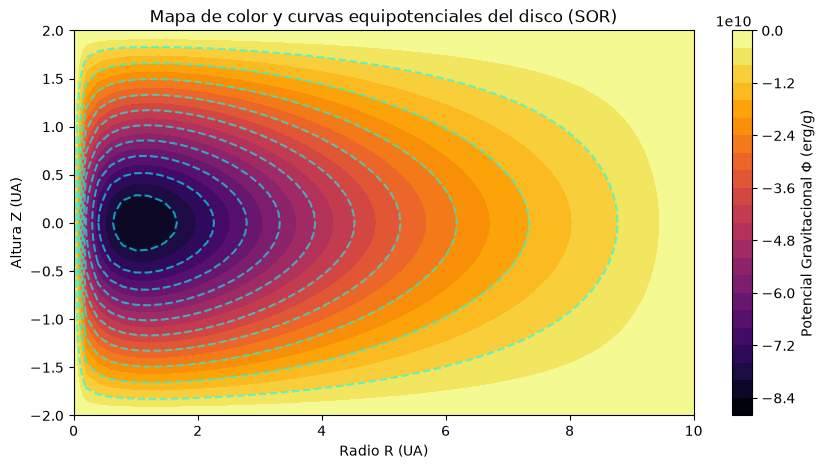

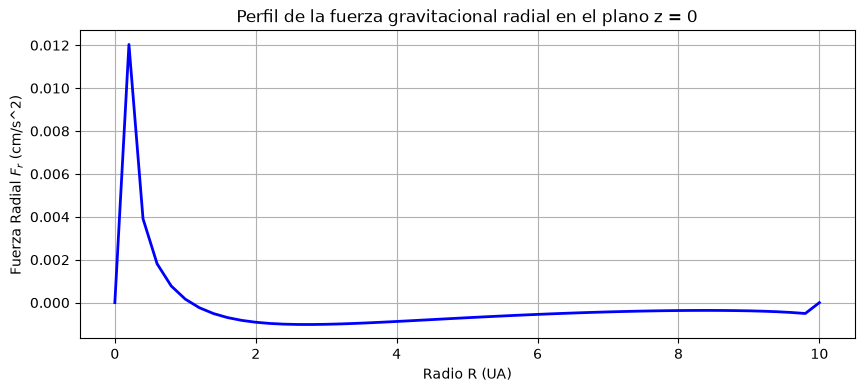

In [7]:
#Gráficos

plt.figure(figsize=(10, 5))
plt.contourf(R_grid / UA, Z_grid / UA, Phi_sor, levels=25, cmap='inferno')
plt.colorbar(label=r'Potencial Gravitacional $\Phi$ (erg/g)')
plt.contour(R_grid / UA, Z_grid / UA, Phi_sor, levels=12, colors='cyan', alpha=0.6)
plt.xlabel('Radio R (UA)')
plt.ylabel('Altura Z (UA)')
plt.title('Mapa de color y curvas equipotenciales del disco (SOR)')
plt.show()

Fr = np.zeros_like(Phi_sor)
for i in range(1, Nr):
    Fr[i, :] = -(Phi_sor[i+1, :] - Phi_sor[i-1, :]) / (2.0 * dr)

plt.figure(figsize=(10, 4))
indice_plano_z0 = int(len(z) / 2)

plt.plot(r / UA, Fr[:, indice_plano_z0], color='blue', linewidth=2)

plt.xlabel('Radio R (UA)')
plt.ylabel(r'Fuerza Radial $F_r$ (cm/s^2)')
plt.title('Perfil de la fuerza gravitacional radial en el plano z = 0')
plt.grid(True)
plt.show()